# Perfis de vinhos tintos semelhantes e atípicos
### Distância Euclidiana em Python + interpretação por LLM (Groq)

**Pergunta:** quais vinhos têm composição físico-química mais parecida entre si e quais se afastam mais do perfil geral da base?

**Dataset:** [Red Wine Quality](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009) (UCI / Kaggle) · 1.599 vinhos · 11 medidas de laboratório + nota de 0 a 10 · sem dados pessoais.

#### Resumo em 1 minuto

| | Resultado |
| --- | --- |
| **Mais parecidos** | Pares quase idênticos (distância 0,015 contra 4,36 na média); os 10 mais próximos são todos linhas vizinhas no arquivo: provavelmente o mesmo vinho medido de novo |
| **Mais atípicos** | Fogem do padrão por 1 ou 2 extremos: sal e sulfatos, açúcar residual ou SO2 total |
| **Qualidade** | Nota alta = mais álcool e menos acidez volátil. Ser atípico não indica nota pior |
| **LLM** | Descreveu bem os números, mas fez uma generalização que os dados não sustentam e errou detalhes que só a conferência pegou |

> Regra do trabalho: o Python produz os resultados primeiro. A LLM só entra depois, para interpretar o resumo.

In [1]:
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

PASTA_DADOS = Path("data")
PASTA_SAIDAS = Path("outputs")
PASTA_SAIDAS.mkdir(exist_ok=True)

# Estilo dos gráficos: cores validadas para daltonismo, grade discreta, sem bordas extras
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#b8b7b1"
TEXTO, TEXTO_SECUNDARIO = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#d4d3cd",
    "axes.labelcolor": TEXTO_SECUNDARIO,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlecolor": TEXTO,
    "axes.titlepad": 12,
    "axes.axisbelow": True,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#ebeae6",
    "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SECUNDARIO,
    "ytick.color": TEXTO_SECUNDARIO,
    "font.size": 11,
    "legend.frameon": False,
})

## 1. Os dados

Cada linha é **um vinho tinto** da denominação portuguesa **Vinho Verde**, analisado em laboratório (Cortez et al., 2009). Os nomes das colunas foram traduzidos para o português (o arquivo original usa `;` como separador).

In [2]:
NOMES = {
    "fixed acidity": "acidez_fixa",
    "volatile acidity": "acidez_volatil",
    "citric acid": "acido_citrico",
    "residual sugar": "acucar_residual",
    "chlorides": "cloretos",
    "free sulfur dioxide": "so2_livre",
    "total sulfur dioxide": "so2_total",
    "density": "densidade",
    "pH": "ph",
    "sulphates": "sulfatos",
    "alcohol": "alcool",
    "quality": "qualidade",
}

df_bruto = pd.read_csv(PASTA_DADOS / "winequality-red.csv", sep=";").rename(columns=NOMES)
df_bruto.index.name = "id_vinho"

print(f"Registros: {df_bruto.shape[0]} | Atributos: {df_bruto.shape[1]}")
df_bruto.head()

Registros: 1599 | Atributos: 12


,acidez_fixa,acidez_volatil,acido_citrico,acucar_residual,cloretos,so2_livre,so2_total,densidade,ph,sulfatos,alcool,qualidade
id_vinho,,,,,,,,,,,,
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5


| Atributo | Significado | Unidade |
| --- | --- | --- |
| `acidez_fixa` | ácidos não voláteis (principalmente tartárico) | g/dm³ |
| `acidez_volatil` | ácido acético; em excesso dá gosto de vinagre | g/dm³ |
| `acido_citrico` | acrescenta "frescor" | g/dm³ |
| `acucar_residual` | açúcar que sobra após a fermentação | g/dm³ |
| `cloretos` | quantidade de sal | g/dm³ |
| `so2_livre` / `so2_total` | dióxido de enxofre (conservante): livre / livre + combinado | mg/dm³ |
| `densidade` | densidade do líquido | g/cm³ |
| `ph` | acidez em escala de pH | — |
| `sulfatos` | aditivo que contribui para o SO2 | g/dm³ |
| `alcool` | teor alcoólico | % vol. |
| `qualidade` | nota sensorial de especialistas (0 a 10) | — |

In [3]:
# Estatísticas descritivas completas (consulta; fora da apresentação)
df_bruto.describe().T

,count,mean,std,min,25%,50%,75%,max
acidez_fixa,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
acidez_volatil,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
acido_citrico,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
acucar_residual,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
cloretos,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
so2_livre,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
so2_total,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
densidade,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
ph,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulfatos,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


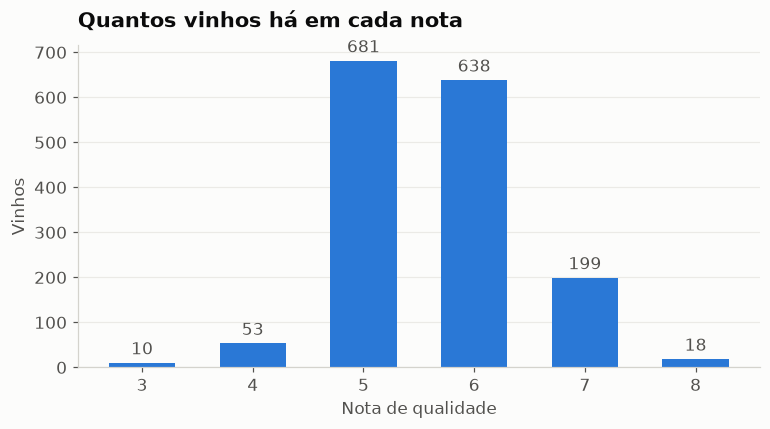

In [4]:
contagem_qualidade = df_bruto["qualidade"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.8))
barras = ax.bar(contagem_qualidade.index.astype(str), contagem_qualidade.to_numpy(), color=AZUL, width=0.6)
ax.bar_label(barras, padding=3, color=TEXTO_SECUNDARIO)
ax.set(title="Quantos vinhos há em cada nota", xlabel="Nota de qualidade", ylabel="Vinhos")
plt.show()

> **Achado:** as notas são desbalanceadas: a maioria dos vinhos (82%) tem nota 5 ou 6, e há poucos nos extremos (10 com nota 3, 53 com nota 4 e 18 com nota 8). Isso limita conclusões sobre vinhos muito bons ou muito ruins.

## 2. Preparação dos dados

### 2.1 Ausentes e duplicidades

In [5]:
print(f"Valores ausentes na base inteira: {df_bruto.isna().sum().sum()}")

duplicados = df_bruto.duplicated()
print(f"Linhas duplicadas (cópia exata de uma linha anterior): {duplicados.sum()}")

df = df_bruto[~duplicados].copy()
print(f"Vinhos após remover as duplicatas: {len(df)}")

Valores ausentes na base inteira: 0
Linhas duplicadas (cópia exata de uma linha anterior): 240
Vinhos após remover as duplicatas: 1359


> **Decisão:** remover as 240 duplicatas. Uma cópia teria distância 0 até o original e apareceria, sem sentido, como "o par mais semelhante".

### 2.2 Outliers por atributo

- **IQR:** valor abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR.
- **Z-score:** valor a mais de 3 desvios-padrão da média.

In [6]:
ATRIBUTOS_ORIGINAIS = [c for c in df.columns if c != "qualidade"]


def outliers_iqr(serie, fator=1.5):
    """Marca os valores fora do intervalo [Q1 - fator*IQR, Q3 + fator*IQR]."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - fator * iqr) | (serie > q3 + fator * iqr)


def outliers_zscore(serie, limite=3):
    """Marca os valores com |z| maior que o limite."""
    z = (serie - serie.mean()) / serie.std()
    return z.abs() > limite


flags_iqr = df[ATRIBUTOS_ORIGINAIS].apply(outliers_iqr)
flags_z = df[ATRIBUTOS_ORIGINAIS].apply(outliers_zscore)
tabela_outliers = pd.DataFrame({"IQR": flags_iqr.sum(), "Z-score": flags_z.sum()})

vinhos_com_outlier_iqr = flags_iqr.any(axis=1).sum()
vinhos_com_outlier_z = flags_z.any(axis=1).sum()

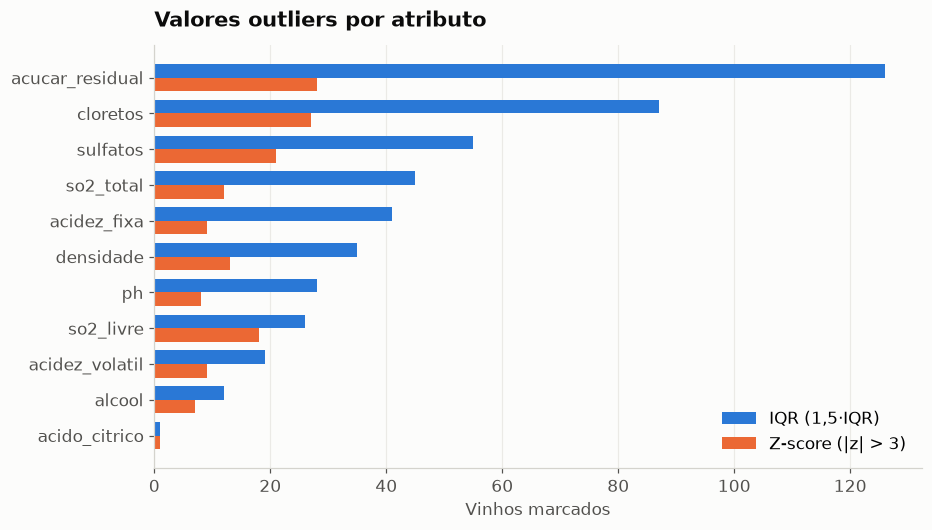

Vinhos com pelo menos um atributo outlier: 340 pelo IQR (25%) e 120 pelo Z-score (9%)


In [7]:
ordem = tabela_outliers.sort_values("IQR")
posicoes = np.arange(len(ordem))
altura = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(posicoes + altura / 2, ordem["IQR"], height=altura, color=AZUL, label="IQR (1,5·IQR)")
ax.barh(posicoes - altura / 2, ordem["Z-score"], height=altura, color=LARANJA, label="Z-score (|z| > 3)")
ax.set_yticks(posicoes, ordem.index)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set(title="Valores outliers por atributo", xlabel="Vinhos marcados")
ax.legend(loc="lower right")
plt.show()

print(f"Vinhos com pelo menos um atributo outlier: {vinhos_com_outlier_iqr} pelo IQR ({vinhos_com_outlier_iqr / len(df):.0%}) "
      f"e {vinhos_com_outlier_z} pelo Z-score ({vinhos_com_outlier_z / len(df):.0%})")

> **Achado:** o IQR marca bem mais valores que o Z-score, porque atributos como açúcar residual, cloretos e sulfatos têm cauda longa à direita.
>
> **Decisão:** os outliers **não** foram removidos. A pergunta é justamente quais vinhos fogem do padrão; as marcações servem para conferir o resultado da distância na seção 3.

### 2.3 Engenharia e seleção de atributos

- **Criados:** `proporcao_so2_livre = so2_livre / so2_total` (fração do SO2 que está livre) e `acidez_total = acidez_fixa + acidez_volatil`.
- **Usados na distância (11):** as medidas originais, trocando `so2_livre` pela proporção, para não contar o SO2 duas vezes.
- **Fora da distância:** `acidez_total` (praticamente uma cópia de `acidez_fixa`) e `qualidade` (a pergunta é sobre composição; a nota é usada depois, para interpretar).

In [8]:
df["proporcao_so2_livre"] = df["so2_livre"] / df["so2_total"]
df["acidez_total"] = df["acidez_fixa"] + df["acidez_volatil"]

print(f"Correlação so2_livre x so2_total: {df['so2_livre'].corr(df['so2_total']):.2f}")
print(f"Correlação acidez_fixa x acidez_total: {df['acidez_fixa'].corr(df['acidez_total']):.2f}")

Correlação so2_livre x so2_total: 0.67
Correlação acidez_fixa x acidez_total: 0.99


### 2.4 Padronização

As escalas são muito diferentes: `so2_total` vai de 6 a 289, enquanto `densidade` fica perto de 0,99. Sem padronizar, a distância seria dominada pelo SO2. O `StandardScaler` deixa cada atributo com média 0 e desvio 1 (z-score).

In [9]:
ATRIBUTOS_DISTANCIA = [
    "acidez_fixa", "acidez_volatil", "acido_citrico", "acucar_residual", "cloretos",
    "so2_total", "proporcao_so2_livre", "densidade", "ph", "sulfatos", "alcool",
]

escalador = StandardScaler()
df_padronizado = pd.DataFrame(
    escalador.fit_transform(df[ATRIBUTOS_DISTANCIA]),
    columns=ATRIBUTOS_DISTANCIA,
    index=df.index,
)

print("Antes: amplitude de cada atributo")
print((df[ATRIBUTOS_DISTANCIA].max() - df[ATRIBUTOS_DISTANCIA].min()).round(2).to_string(), end="\n\n")
print(f"Depois: médias entre {df_padronizado.mean().min():.2f} e {df_padronizado.mean().max():.2f}, desvios = 1")

Antes: amplitude de cada atributo
acidez_fixa             11.30
acidez_volatil           1.46
acido_citrico            1.00
acucar_residual         14.60
cloretos                 0.60
so2_total              283.00
proporcao_so2_livre      0.83
densidade                0.01
ph                       1.27
sulfatos                 1.67
alcool                   6.50

Depois: médias entre -0.00 e 0.00, desvios = 1


## 3. Mineração: vinhos mais parecidos

Distância Euclidiana entre **todos** os pares de vinhos, nos 11 atributos padronizados.

In [10]:
matriz = df_padronizado.to_numpy()
distancias = pdist(matriz, metric="euclidean")  # cada par uma vez, na ordem de np.triu_indices
indice_a, indice_b = np.triu_indices(len(matriz), k=1)

print(f"Pares comparados: {len(distancias):,}".replace(",", "."))
print(f"Distância média entre dois vinhos: {distancias.mean():.2f}")
print(f"Menor distância: {distancias.min():.3f} | Maior: {distancias.max():.2f}")

Pares comparados: 922.761
Distância média entre dois vinhos: 4.36
Menor distância: 0.015 | Maior: 18.11


In [11]:
def pares_mais_proximos(n=10):
    """Os n pares com menor distância, com a nota de cada vinho."""
    ordem = np.argsort(distancias)[:n]
    vinho_a = df.index[indice_a[ordem]]
    vinho_b = df.index[indice_b[ordem]]
    return pd.DataFrame({
        "vinho_a": vinho_a,
        "vinho_b": vinho_b,
        "distancia": distancias[ordem],
        "nota_a": df.loc[vinho_a, "qualidade"].to_numpy(),
        "nota_b": df.loc[vinho_b, "qualidade"].to_numpy(),
    })


tabela_pares = pares_mais_proximos(10)
tabela_pares.to_csv(PASTA_SAIDAS / "pares_mais_semelhantes.csv", index=False)
tabela_pares.head(5)

,vinho_a,vinho_b,distancia,nota_a,nota_b
0,1514,1515,0.015,6,6
1,1439,1444,0.031,6,6
2,1475,1477,0.031,7,7
3,1441,1445,0.031,6,6
4,1191,1193,0.058,5,5


> **Achado:** os pares mais próximos são **quase idênticos** (0,015 contra 4,36 na média) e os 10 mais próximos são todos **linhas vizinhas** no arquivo (1514 e 1515, 1439 e 1444…). O par mais próximo só difere no álcool (9,233 contra 9,25). Hipótese: é o mesmo vinho, ou o mesmo lote, medido de novo.

In [12]:
# O par mais próximo lado a lado, em valores originais (consulta; fora da apresentação)
par = tabela_pares.iloc[0]
df.loc[[par["vinho_a"], par["vinho_b"]], ATRIBUTOS_DISTANCIA + ["qualidade"]].T

id_vinho,1514,1515
acidez_fixa,6.900,6.900
acidez_volatil,0.840,0.840
acido_citrico,0.210,0.210
acucar_residual,4.100,4.100
cloretos,0.074,0.074
so2_total,65.000,65.000
proporcao_so2_livre,0.246,0.246
densidade,0.998,0.998
ph,3.530,3.530
sulfatos,0.720,0.720


### Vinhos parecidos têm a mesma nota?

Se a composição tem relação com a qualidade, os pares mais próximos deveriam ter a mesma nota com mais frequência do que dois vinhos quaisquer.

Cuidado: linhas vizinhas no arquivo (provável medição repetida do mesmo vinho) têm a mesma nota naturalmente. Por isso a comparação também é feita **sem** os pares de linhas vizinhas (ids a até 5 linhas de distância).

Dos 100 pares mais próximos, 52 são linhas vizinhas no arquivo


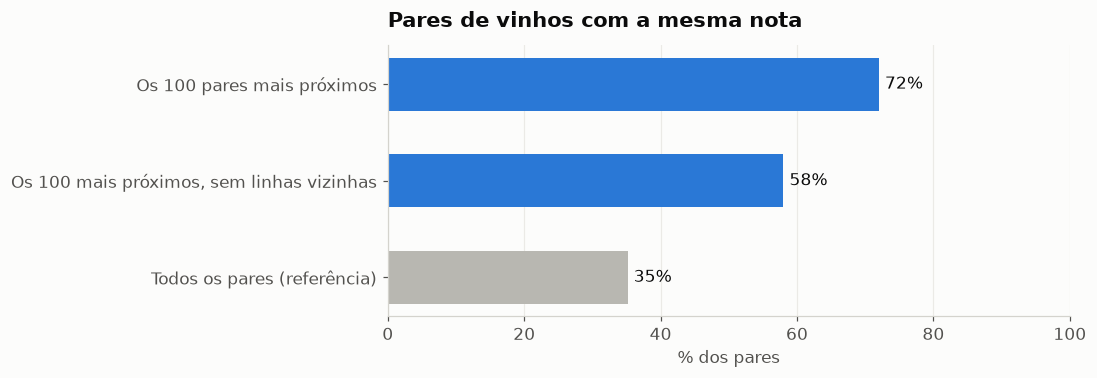

In [13]:
qualidades = df["qualidade"].to_numpy()
mesma_nota = qualidades[indice_a] == qualidades[indice_b]
ids = df.index.to_numpy()
vizinhos = np.abs(ids[indice_a] - ids[indice_b]) <= 5

TOP_PARES = 100
ordem_proximos = np.argsort(distancias)[:TOP_PARES]
ordem_sem_vizinhos = np.argsort(np.where(vizinhos, np.inf, distancias))[:TOP_PARES]
taxa_proximos = mesma_nota[ordem_proximos].mean()
taxa_sem_vizinhos = mesma_nota[ordem_sem_vizinhos].mean()
taxa_geral = mesma_nota.mean()
print(f"Dos {TOP_PARES} pares mais próximos, {vizinhos[ordem_proximos].sum()} são linhas vizinhas no arquivo")

fig, ax = plt.subplots(figsize=(8, 3.2))
rotulos = [
    f"Os {TOP_PARES} pares mais próximos",
    f"Os {TOP_PARES} mais próximos, sem linhas vizinhas",
    "Todos os pares (referência)",
]
valores = [taxa_proximos * 100, taxa_sem_vizinhos * 100, taxa_geral * 100]
barras = ax.barh(rotulos, valores, color=[AZUL, AZUL, CINZA], height=0.55)
ax.bar_label(barras, labels=[f"{v:.0f}%" for v in valores], padding=4, color=TEXTO)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set(title="Pares de vinhos com a mesma nota", xlabel="% dos pares")
plt.show()

> **Achado:** 72% dos 100 pares mais próximos têm a mesma nota, mas esse número está inflado: 52 desses pares são linhas vizinhas, que naturalmente têm a mesma nota. Sem elas, **58%** dos pares mais próximos têm a mesma nota, contra 35% entre todos os pares. A composição tem relação com a qualidade, mas não a determina sozinha.

## 3. Mineração: vinhos mais atípicos

Com os dados padronizados, o centro da base (o vinho "médio") é o ponto onde todos os atributos valem 0. A distância de cada vinho até esse centro mede o quanto ele foge do perfil geral. O "motivo" mostra os atributos com maior |z|.

In [14]:
distancia_ao_centro = pd.Series(np.linalg.norm(matriz, axis=1), index=df.index, name="distancia_ao_centro")
LIMITE_ATIPICO = distancia_ao_centro.quantile(0.95)
atipicos_5 = distancia_ao_centro > LIMITE_ATIPICO


def motivo(id_vinho, n=2):
    """Os n atributos que mais afastam o vinho do centro, com valor original e mediana da base."""
    z = df_padronizado.loc[id_vinho]
    principais = z.abs().sort_values(ascending=False).index[:n]
    partes = []
    for atributo in principais:
        valor = df.loc[id_vinho, atributo]
        mediana = df[atributo].median()
        partes.append(f"{atributo} = {valor:.4g} (mediana {mediana:.4g}, z = {z[atributo]:+.1f})")
    return "; ".join(partes)


def vinhos_mais_atipicos(n=10):
    """Os n vinhos mais distantes do centro, com nota, quantidade de outliers e motivo."""
    ids = distancia_ao_centro.nlargest(n).index
    return pd.DataFrame({
        "distancia_ao_centro": distancia_ao_centro[ids],
        "nota": df.loc[ids, "qualidade"],
        "outliers_z": flags_z.loc[ids].sum(axis=1),
        "outliers_iqr": flags_iqr.loc[ids].sum(axis=1),
        "motivo": [motivo(i) for i in ids],
    })


tabela_atipicos = vinhos_mais_atipicos(10)
tabela_atipicos.to_csv(PASTA_SAIDAS / "vinhos_mais_atipicos.csv")
with pd.option_context("display.max_colwidth", None):
    display(tabela_atipicos[["distancia_ao_centro", "nota", "motivo"]])

,distancia_ao_centro,nota,motivo
id_vinho,,,
151,14.342,4,"cloretos = 0.61 (mediana 0.079, z = +10.6); sulfatos = 2 (mediana 0.62, z = +7.9)"
258,11.703,5,"cloretos = 0.611 (mediana 0.079, z = +10.6); sulfatos = 1.26 (mediana 0.62, z = +3.5)"
1434,10.919,6,"acucar_residual = 15.4 (mediana 2.2, z = +9.5); densidade = 1.004 (mediana 0.9967, z = +3.7)"
480,10.494,5,"acucar_residual = 15.5 (mediana 2.2, z = +9.6); densidade = 1.003 (mediana 0.9967, z = +3.2)"
1474,9.649,5,"acucar_residual = 13.8 (mediana 2.2, z = +8.3); densidade = 1.002 (mediana 0.9967, z = +3.1)"
1081,9.548,7,"so2_total = 289 (mediana 38, z = +7.3); acucar_residual = 8.3 (mediana 2.2, z = +4.3)"
1079,9.295,7,"so2_total = 278 (mediana 38, z = +6.9); acucar_residual = 8.3 (mediana 2.2, z = +4.3)"
1574,9.244,6,"acucar_residual = 13.9 (mediana 2.2, z = +8.4); acido_citrico = 0.78 (mediana 0.26, z = +2.6)"
106,9.120,5,"cloretos = 0.467 (mediana 0.079, z = +7.7); sulfatos = 1.31 (mediana 0.62, z = +3.8)"


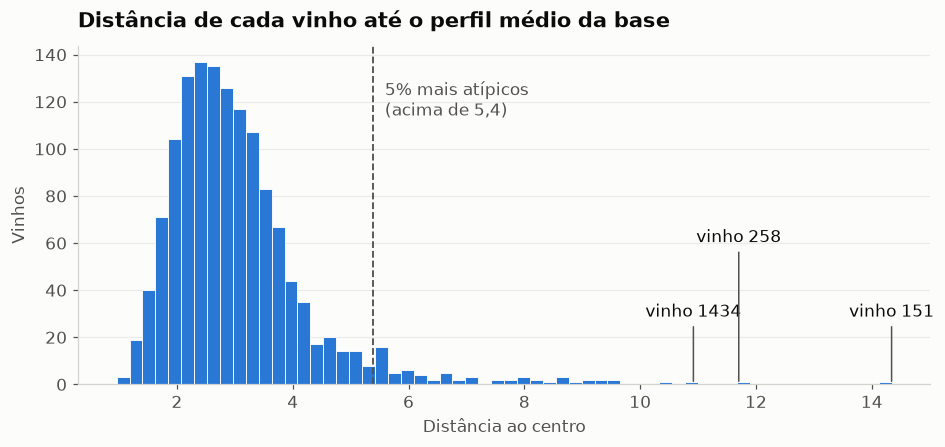

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(distancia_ao_centro, bins=60, color=AZUL, edgecolor="#fcfcfb", linewidth=0.6)
ax.axvline(LIMITE_ATIPICO, color=TEXTO_SECUNDARIO, linestyle="--", linewidth=1.2)
ax.text(LIMITE_ATIPICO + 0.2, ax.get_ylim()[1] * 0.9, f"5% mais atípicos\n(acima de {LIMITE_ATIPICO:.1f})".replace(".", ","),
        color=TEXTO_SECUNDARIO, va="top")
# rótulos em alturas alternadas para não se sobreporem
for altura, (id_vinho, distancia) in zip([0.2, 0.42, 0.2], distancia_ao_centro.nlargest(3).sort_values().items()):
    ax.annotate(f"vinho {id_vinho}", xy=(distancia, 0), xytext=(distancia, ax.get_ylim()[1] * altura),
                ha="center", color=TEXTO, arrowprops={"arrowstyle": "-", "color": TEXTO_SECUNDARIO})
ax.set(title="Distância de cada vinho até o perfil médio da base", xlabel="Distância ao centro", ylabel="Vinhos")
plt.show()

> **Achado:** a maioria dos vinhos fica perto do centro (mediana 2,8), mas há uma cauda longa. Os mais atípicos fogem por **um ou dois extremos**, em três tipos:
> - **sal e sulfatos** (vinhos 151, 258, 106): cloretos até 0,61 g/dm³, contra mediana de 0,079;
> - **açúcar residual** (1434, 480, 1474): até 15,5 g/dm³, contra 2,2. Por isso também são mais densos;
> - **SO2 total** (1081, 1079): 289 e 278 mg/dm³, contra 38.

### Conferência com os outliers da seção 2.2

Se a distância e as técnicas de outlier concordam, os vinhos mais atípicos devem ter atributos marcados como outlier.

In [16]:
print(f"Dos 10 mais atípicos, com pelo menos um outlier Z-score: {(tabela_atipicos['outliers_z'] > 0).sum()} de 10")
print(f"Dos 10 mais atípicos, com pelo menos um outlier IQR: {(tabela_atipicos['outliers_iqr'] > 0).sum()} de 10")

principal_atributo = df_padronizado.loc[atipicos_5].abs().idxmax(axis=1)
print(f"\nAtributo que mais afasta cada um dos {atipicos_5.sum()} vinhos mais atípicos (5%):")
print(principal_atributo.value_counts().head(5).to_string())

Dos 10 mais atípicos, com pelo menos um outlier Z-score: 10 de 10
Dos 10 mais atípicos, com pelo menos um outlier IQR: 10 de 10

Atributo que mais afasta cada um dos 68 vinhos mais atípicos (5%):
cloretos           21
acucar_residual    13
sulfatos            7
alcool              6
acidez_fixa         6


> **Achado:** os 10 vinhos mais atípicos pela distância também são outliers pelo IQR e pelo Z-score. Com o Z-score isso já era esperado, porque a distância ao centro e o Z-score usam os mesmos valores padronizados. O IQR, que usa quartis, é a conferência mais independente, e também concorda.

## 3. Mineração: por faixa de qualidade

Faixas: **baixa** (notas 3–4), **média** (5–6) e **alta** (7–8). Agregações com Pandas.

In [17]:
df["faixa_qualidade"] = pd.cut(df["qualidade"], bins=[2, 4, 6, 8], labels=["baixa (3-4)", "média (5-6)", "alta (7-8)"])
df["distancia_ao_centro"] = distancia_ao_centro
df["atipico_5pct"] = atipicos_5

ATRIBUTOS_RESUMO = ["alcool", "acidez_volatil", "sulfatos", "acido_citrico", "densidade", "so2_total"]

por_faixa = df.groupby("faixa_qualidade", observed=True).agg(
    vinhos=("qualidade", "size"),
    **{atributo: (atributo, "mean") for atributo in ATRIBUTOS_RESUMO},
    distancia_media_ao_centro=("distancia_ao_centro", "mean"),
    pct_atipicos=("atipico_5pct", "mean"),
)
por_faixa["pct_atipicos"] = (por_faixa["pct_atipicos"] * 100).round(1)
por_faixa.to_csv(PASTA_SAIDAS / "estatisticas_por_faixa.csv")
por_faixa

,vinhos,alcool,acidez_volatil,sulfatos,acido_citrico,densidade,so2_total,distancia_media_ao_centro,pct_atipicos
faixa_qualidade,,,,,,,,,
baixa (3-4),63,10.216,0.724,0.592,0.174,0.997,34.444,3.530,6.3
média (5-6),1112,10.259,0.539,0.648,0.261,0.997,49.425,2.978,4.9
alta (7-8),184,11.553,0.406,0.746,0.373,0.996,35.359,3.354,5.4


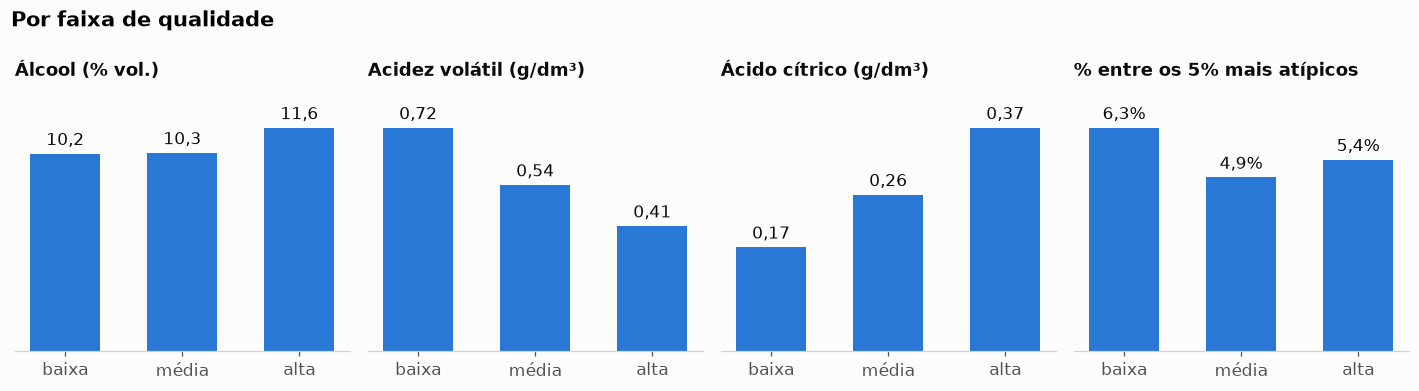

In [18]:
PAINEIS = [
    ("alcool", "Álcool (% vol.)", "{:.1f}"),
    ("acidez_volatil", "Acidez volátil (g/dm³)", "{:.2f}"),
    ("acido_citrico", "Ácido cítrico (g/dm³)", "{:.2f}"),
    ("pct_atipicos", "% entre os 5% mais atípicos", "{:.1f}%"),
]

fig, eixos = plt.subplots(1, len(PAINEIS), figsize=(13, 3.6))
for ax, (coluna, titulo, formato) in zip(eixos, PAINEIS):
    barras = ax.bar(["baixa", "média", "alta"], por_faixa[coluna], color=AZUL, width=0.6)
    ax.bar_label(barras, labels=[formato.format(v).replace(".", ",") for v in por_faixa[coluna]], padding=3, color=TEXTO)
    ax.set_title(titulo, fontsize=12)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.grid(False)
    ax.margins(y=0.15)
fig.suptitle("Por faixa de qualidade", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout()
plt.show()

> **Achado:** vinhos de nota alta têm **mais álcool** (11,6 contra 10,2) e **menos acidez volátil** (0,41 contra 0,72), que é o ácido do gosto de vinagre. Mas **ser atípico não indica nota pior**: a fração de atípicos é parecida nas três faixas (6,3%, 4,9% e 5,4%). A faixa baixa é um pouco maior, mas são só 4 de 63 vinhos.

## 4. Resumo enviado à LLM

Montado **somente** com resultados já calculados: contagens, pares mais próximos, vinhos atípicos com o motivo e médias por faixa. Nenhuma linha do CSV é enviada.

In [19]:
def formatar_tabela_faixas():
    linhas = []
    for faixa, linha in por_faixa.iterrows():
        medias = ", ".join(f"{a} {linha[a]:.3g}" for a in ATRIBUTOS_RESUMO)
        linhas.append(
            f"- {faixa}: {int(linha['vinhos'])} vinhos; médias: {medias}; "
            f"distância média ao centro {linha['distancia_media_ao_centro']:.2f}; "
            f"{linha['pct_atipicos']:.1f}% entre os 5% mais atípicos"
        )
    return "\n".join(linhas)


def formatar_pares(n=5):
    return "\n".join(
        f"- Vinho {p.vinho_a} e vinho {p.vinho_b}: distância {p.distancia:.3f} (notas {p.nota_a} e {p.nota_b})"
        for p in tabela_pares.head(n).itertuples()
    )


def formatar_atipicos(n=5):
    return "\n".join(
        f"- Vinho {i}: distância ao centro {linha.distancia_ao_centro:.2f}, nota {linha.nota}; motivo: {linha.motivo}"
        for i, linha in tabela_atipicos.head(n).iterrows()
    )


contagem_motivos = principal_atributo.value_counts()

resumo = f"""Dataset: Red Wine Quality (vinhos tintos, medidas físico-químicas de laboratório e nota de qualidade de 0 a 10).
Registros: {len(df_bruto)} no arquivo; {duplicados.sum()} duplicatas exatas removidas; {len(df)} vinhos analisados. Sem valores ausentes.

Preparação:
- Atributos usados na distância (11, padronizados por z-score): {", ".join(ATRIBUTOS_DISTANCIA)}.
- proporcao_so2_livre = so2_livre / so2_total (atributo criado). A nota de qualidade NÃO entrou na distância.
- Vinhos com pelo menos um atributo outlier: {vinhos_com_outlier_iqr} pelo IQR (1,5·IQR) e {vinhos_com_outlier_z} pelo Z-score (|z| > 3).
- Atributos com mais outliers pelo IQR: {", ".join(f"{a} ({n})" for a, n in tabela_outliers["IQR"].nlargest(3).items())}.

Similaridade (distância Euclidiana entre todos os {len(distancias)} pares):
- Distância média entre dois vinhos: {distancias.mean():.2f}; menor: {distancias.min():.3f}; maior: {distancias.max():.2f}.
- Pares mais semelhantes:
{formatar_pares()}
- Entre os {TOP_PARES} pares mais próximos, {taxa_proximos:.1%} têm a mesma nota; entre todos os pares, {taxa_geral:.1%}.

Vinhos mais atípicos (distância ao centro da base; mediana da base = {distancia_ao_centro.median():.2f}):
{formatar_atipicos()}
- Os 5% mais distantes do centro ({atipicos_5.sum()} vinhos) estão acima de {LIMITE_ATIPICO:.2f}.
- Atributo que mais afasta cada um desses vinhos: {", ".join(f"{a} ({n})" for a, n in contagem_motivos.head(4).items())}.

Médias por faixa de qualidade:
{formatar_tabela_faixas()}
"""

(PASTA_SAIDAS / "resumo_estruturado.txt").write_text(resumo, encoding="utf-8")
print(resumo)

Dataset: Red Wine Quality (vinhos tintos, medidas físico-químicas de laboratório e nota de qualidade de 0 a 10).
Registros: 1599 no arquivo; 240 duplicatas exatas removidas; 1359 vinhos analisados. Sem valores ausentes.

Preparação:
- Atributos usados na distância (11, padronizados por z-score): acidez_fixa, acidez_volatil, acido_citrico, acucar_residual, cloretos, so2_total, proporcao_so2_livre, densidade, ph, sulfatos, alcool.
- proporcao_so2_livre = so2_livre / so2_total (atributo criado). A nota de qualidade NÃO entrou na distância.
- Vinhos com pelo menos um atributo outlier: 340 pelo IQR (1,5·IQR) e 120 pelo Z-score (|z| > 3).
- Atributos com mais outliers pelo IQR: acucar_residual (126), cloretos (87), sulfatos (55).

Similaridade (distância Euclidiana entre todos os 922761 pares):
- Distância média entre dois vinhos: 4.36; menor: 0.015; maior: 18.11.
- Pares mais semelhantes:
- Vinho 1514 e vinho 1515: distância 0.015 (notas 6 e 6)
- Vinho 1439 e vinho 1444: distância 0.031 (no

## 5. Integração com a LLM via API (Groq)

O prompt tem três partes:
- **Contexto:** o que os dados representam e como o resumo foi produzido;
- **Limites:** usar só os números fornecidos, não inventar valores, marcar hipóteses;
- **Saída:** formato em seções.

A chave **não** fica no código: ela é lida do arquivo `.env` (que está no `.gitignore`).

A resposta vem em Markdown (o prompt pede isso), por isso é salva como `.md`. A LLM dá uma resposta um pouco diferente a cada chamada. Por isso o notebook **reaproveita a resposta salva** em `outputs/resposta_llm.md`, que é a resposta avaliada na seção 6: assim a análise e a avaliação ficam sempre consistentes. Para consultar a LLM de novo, mude `CONSULTAR_LLM_DE_NOVO` para `True` (e reescreva a avaliação da seção 6 para a nova resposta).

In [20]:
INSTRUCAO_SISTEMA = (
    "Você é um analista de dados que interpreta resultados de Mineração de Dados. "
    "Interprete somente as informações fornecidas. Não invente valores, vinhos ou atributos que não estejam no resumo. "
    "Quando sugerir uma explicação que não pode ser comprovada pelos números, deixe claro que é uma hipótese."
)

PEDIDO = f"""Você receberá resultados produzidos por uma análise de Mineração de Dados feita em Python sobre vinhos tintos.
Cada vinho é descrito por medidas físico-químicas padronizadas; a semelhança foi medida pela distância Euclidiana.

Responda em português, em Markdown, com estas seções:
1. Principais padrões: o que distingue as faixas de qualidade.
2. Vinhos mais semelhantes: o que a proximidade indica e se ela tem relação com a nota.
3. Vinhos atípicos: por que se afastam do perfil geral e possíveis explicações (marque como hipótese).
4. Conclusão curta (até 5 linhas) respondendo: quais vinhos são mais parecidos entre si e quais se afastam mais do perfil geral?
5. Duas perguntas adicionais que valeria investigar.

Resumo dos resultados:
{resumo}"""

mensagens = [
    {"role": "system", "content": INSTRUCAO_SISTEMA},
    {"role": "user", "content": PEDIDO},
]

(PASTA_SAIDAS / "prompt.txt").write_text(f"[system]\n{INSTRUCAO_SISTEMA}\n\n[user]\n{PEDIDO}", encoding="utf-8")
print(f"Prompt salvo em {PASTA_SAIDAS / 'prompt.txt'}")

Prompt salvo em outputs/prompt.txt


In [21]:
from dotenv import load_dotenv
from groq import Groq

CONSULTAR_LLM_DE_NOVO = False  # True = chamar a API mesmo já existindo uma resposta salva

MODELO = "openai/gpt-oss-120b"
ARQUIVO_RESPOSTA = PASTA_SAIDAS / "resposta_llm.md"


def consultar_llm(mensagens, modelo=MODELO):
    """Envia o prompt para a API da Groq e devolve o texto da resposta."""
    load_dotenv()
    if not os.getenv("GROQ_API_KEY"):
        raise RuntimeError("Chave da Groq não encontrada: copie .env.example para .env e preencha GROQ_API_KEY.")
    cliente = Groq()  # lê GROQ_API_KEY do ambiente
    resposta = cliente.chat.completions.create(model=modelo, messages=mensagens, temperature=0.2)
    return resposta.choices[0].message.content


if ARQUIVO_RESPOSTA.exists() and not CONSULTAR_LLM_DE_NOVO:
    resposta_llm = ARQUIVO_RESPOSTA.read_text(encoding="utf-8")
    print(f"Usando a resposta salva em {ARQUIVO_RESPOSTA} (a mesma avaliada na seção 6).")
    print("Para consultar a LLM de novo, mude CONSULTAR_LLM_DE_NOVO para True.")
else:
    resposta_llm = consultar_llm(mensagens)
    ARQUIVO_RESPOSTA.write_text(resposta_llm, encoding="utf-8")
    print(f"Resposta recebida do modelo {MODELO} e salva em {ARQUIVO_RESPOSTA}")

Usando a resposta salva em outputs/resposta_llm.md (a mesma avaliada na seção 6).
Para consultar a LLM de novo, mude CONSULTAR_LLM_DE_NOVO para True.


### Resposta da LLM

In [22]:
display(Markdown(resposta_llm))

## 1. Principais padrões: o que distingue as faixas de qualidade

| Faixa de qualidade | Nº de vinhos | Álcool (° % vol) | Acidez volátil (g/dm³) | Sulfatos (g/dm³) | Ácido cítrico (g/dm³) | Densidade (g/cm³) | SO₂ total (mg/dm³) | Distância média ao centro |
|--------------------|--------------|------------------|------------------------|------------------|-----------------------|-------------------|--------------------|----------------------------|
| **Baixa (3‑4)**    | 63           | 10.2             | 0.724                  | 0.592            | 0.174                 | 0.997             | 34.4               | 3.53                       |
| **Média (5‑6)**    | 1 112        | 10.3             | 0.539                  | 0.648            | 0.261                 | 0.997             | 49.4               | 2.98                       |
| **Alta (7‑8)**     | 184          | 11.6 **↑**       | 0.406 **↓**            | 0.746 **↑**      | 0.373 **↑**           | 0.996 **↓**       | 35.4 **↓**         | 3.35                       |

* Tendência clara: **vinhos de qualidade alta apresentam maior teor alcoólico e maior concentração de sulfatos e ácido cítrico**, ao mesmo tempo em que têm menor acidez volátil, densidade ligeiramente menor e menor teor total de SO₂.
* A faixa média tem valores intermediários, mas destaca‑se pelo **maior SO₂ total** (possível efeito conservante) e pela menor acidez volátil que a baixa, porém ainda acima da alta.
* A distância média ao centro (mediana 2.80) é menor para a faixa média (2.98) que para as faixas baixa (3.53) e alta (3.35), indicando que a maioria dos vinhos “médios” está mais próximo do perfil global.

---

## 2. Vinhos mais semelhantes

| Par de vinhos | Distância | Notas | Observação |
|---------------|-----------|-------|------------|
| 1514 – 1515   | 0.015 | 6 – 6 | Quase idênticos nos 11 atributos padronizados. |
| 1439 – 1444   | 0.031 | 6 – 6 | Muito próximos; mesma nota. |
| 1475 – 1477   | 0.031 | 7 – 7 | Alta qualidade, perfil químico quase igual. |
| 1441 – 1445   | 0.031 | 6 – 6 | Distância mínima entre vinhos de nota média. |
| 1191 – 1193   | 0.058 | 5 – 5 | Ainda muito próximos, nota baixa‑média. |

* **Proporção de pares com mesma nota:** 72 % nos 100 pares mais próximos vs. 35 % no conjunto total de pares.
* **Interpretação:** a proximidade Euclidiana nos atributos padronizados tende a refletir a nota de qualidade, mas não de forma determinística – ainda há pares muito próximos com notas diferentes (não listados aqui). A alta concordância (72 %) indica que vinhos com composição química quase idêntica costumam receber avaliações semelhantes, sugerindo que os atributos selecionados capturam parte da percepção de qualidade.

---

## 3. Vinhos atípicos

| Vinho | Distância ao centro | Nota | Atributos que mais se destacam |
|-------|---------------------|------|--------------------------------|
| 151   | 14.34 | 4 | Cloretos = 0.61 (z = +10.6), Sulfatos = 2 (z = +7.9) |
| 258   | 11.70 | 5 | Cloretos = 0.611 (z = +10.6), Sulfatos = 1.26 (z = +3.5) |
| 1434  | 10.92 | 6 | Açúcar residual = 15.4 (z = +9.5), Densidade = 1.004 (z = +3.7) |
| 480   | 10.49 | 5 | Açúcar residual = 15.5 (z = +9.6), Densidade = 1.003 (z = +3.2) |
| 1474  | 9.65  | 5 | Açúcar residual = 13.8 (z = +8.3), Densidade = 1.002 (z = +3.1) |

* **Por que se afastam?**
  * **Cloretos** e **sulfatos** extremamente altos (vinhos 151 e 258) podem indicar adição excessiva de sal ou processos de vinificação incomuns, o que os coloca longe do “centro” químico.
  * **Açúcar residual** muito elevado (vinhos 1434, 480, 1474) eleva a densidade e cria perfis doces incomuns para vinhos tintos, afastando‑os do padrão geral.
* **Hipóteses:**
  * Esses vinhos podem ser **estilos especiais** (por exemplo, vinhos de sobremesa ou fortificados) que não foram filtrados na seleção original.
  * A presença de valores tão extremos pode refletir **erros de medição ou registro** (por exemplo, unidades equivocadas).
  * O baixo número de notas altas entre os mais atípicos (apenas um 6) sugere que desvios extremos podem estar associados a avaliações menos favoráveis, embora isso precise ser testado estatisticamente.

---

## 4. Conclusão curta

Os pares mais semelhantes são os vinhos 1514‑1515, 1439‑1444, 1475‑1477, 1441‑1445 e 1191‑1193, que apresentam distâncias quase nulas e notas idênticas, indicando forte concordância entre composição química e avaliação. Os vinhos mais afastados do perfil geral são 151, 258, 1434, 480 e 1474, cujos valores extremos de cloretos, sulfatos ou açúcar residual os tornam atípicos.

---

## 5. Perguntas adicionais que valeria investigar

1. **Qual a influência individual de cada atributo (ex.: álcool, sulfatos, açúcar residual) na probabilidade de um vinho receber nota alta, usando modelos de importância de variáveis (e.g., regressão logística ou árvore de decisão)?**
2. **Os vinhos atípicos (especialmente os com cloretos e sulfatos muito altos) pertencem a alguma sub‑categoria de produção (região, tipo de uva, método de vinificação) que justifique esses valores extremos?**

## 6. A LLM acertou?

A resposta não é aceita automaticamente. A célula abaixo confere a resposta com o que o código calculou: números que não estão no resumo, se ela citou os vinhos certos e os fatos que uma boa interpretação precisa respeitar.

In [23]:
PADRAO_NUMERO = r"\d+(?:[.,]\d+)?"


def normalizar_numero(texto):
    return texto.replace(",", ".")


def numeros_fora_do_resumo(resposta, resumo):
    """Números citados na resposta que não aparecem em nenhum lugar do resumo."""
    no_resumo = {normalizar_numero(n) for n in re.findall(PADRAO_NUMERO, resumo)}
    return sorted({n for n in re.findall(PADRAO_NUMERO, resposta) if normalizar_numero(n) not in no_resumo})


def citados(ids, resposta):
    """Quais ids de vinho aparecem na resposta."""
    return [i for i in ids if re.search(rf"\b{i}\b", resposta)]


ids_pares = sorted(set(tabela_pares.head(5)[["vinho_a", "vinho_b"]].to_numpy().ravel()))
ids_atipicos = list(tabela_atipicos.head(5).index)
pares_vizinhos = ((tabela_pares["vinho_a"] - tabela_pares["vinho_b"]).abs() <= 5).sum()
atipicos_nota_alta = tabela_atipicos.index[tabela_atipicos["nota"] >= 7].tolist()
fracao = por_faixa["pct_atipicos"]

print("CONFERÊNCIA AUTOMÁTICA")
print(f"- Números citados que não estão no resumo: {numeros_fora_do_resumo(resposta_llm, resumo) or 'nenhum'}")
print("  (podem ser arredondamentos, números de seção ou valores inventados: conferir um a um)")
print(f"- Vinhos dos 5 pares mais próximos citados: {len(citados(ids_pares, resposta_llm))} de {len(ids_pares)}")
print(f"- Vinhos dos 5 mais atípicos citados: {len(citados(ids_atipicos, resposta_llm))} de {len(ids_atipicos)}")

print("\nFATOS PARA CONFERIR NA RESPOSTA")
print(f"- {pares_vizinhos} dos 10 pares mais próximos são linhas vizinhas no arquivo: a LLM considerou que pode ser o mesmo vinho medido de novo?")
print(f"- Atípicos por faixa: baixa {fracao.iloc[0]:.1f}%, média {fracao.iloc[1]:.1f}%, alta {fracao.iloc[2]:.1f}%. "
      "Se a LLM disse que atípicos têm nota pior, os dados não sustentam.")
print(f"- Entre os 10 mais atípicos há vinhos de nota 7 ou mais: {atipicos_nota_alta or 'nenhum'}")
print("- As faixas são baixa (3-4), média (5-6) e alta (7-8): nota 6 é média, não alta.")
print("- Todos os vinhos são tintos do Vinho Verde (o prompt não informou isso): hipóteses como 'vinho de sobremesa' ou 'fortificado' não se aplicam.")
if re.search(r"sobremesa|fortificad", resposta_llm, re.IGNORECASE):
    print("  -> ATENÇÃO: a resposta fala em vinho de sobremesa/fortificado.")

CONFERÊNCIA AUTOMÁTICA
- Números citados que não estão no resumo: ['1', '112', '35', '72']
  (podem ser arredondamentos, números de seção ou valores inventados: conferir um a um)
- Vinhos dos 5 pares mais próximos citados: 10 de 10
- Vinhos dos 5 mais atípicos citados: 5 de 5

FATOS PARA CONFERIR NA RESPOSTA
- 10 dos 10 pares mais próximos são linhas vizinhas no arquivo: a LLM considerou que pode ser o mesmo vinho medido de novo?
- Atípicos por faixa: baixa 6.3%, média 4.9%, alta 5.4%. Se a LLM disse que atípicos têm nota pior, os dados não sustentam.
- Entre os 10 mais atípicos há vinhos de nota 7 ou mais: [1081, 1079]
- As faixas são baixa (3-4), média (5-6) e alta (7-8): nota 6 é média, não alta.
- Todos os vinhos são tintos do Vinho Verde (o prompt não informou isso): hipóteses como 'vinho de sobremesa' ou 'fortificado' não se aplicam.
  -> ATENÇÃO: a resposta fala em vinho de sobremesa/fortificado.


| | Acertou | Errou ou exagerou |
| --- | --- | --- |
| **Valores** | Médias por faixa, pares mais próximos, 72% contra 35%, motivos dos atípicos | Disse que 1441–1445 tem a "distância mínima" entre vinhos de nota média; a menor é a de 1514–1515 (0,015) |
| **Números** | Nenhum inventado: 1, 112, 35 e 72 são só "1 112" (1112), números de seção e arredondamentos | — |
| **Generalização** | Marcou como hipótese a testar | Sugeriu, com base em só 5 vinhos, que atípicos têm nota menor; os dados não sustentam (fração parecida nas faixas: 6,3%, 4,9% e 5,4%). Concluiu "forte concordância entre composição e avaliação" a partir de 5 pares que provavelmente são medições repetidas |
| **Faixas** | — | Chamou a nota 6 de "alta" (no trabalho, 6 é faixa média) e o par de nota 5 de "baixa-média" |
| **Contexto** | Açúcar alto com densidade alta: faz sentido | Sugeriu vinho de sobremesa, mas todos são tintos do Vinho Verde (informação que o prompt não deu) |
| **O que faltou** | — | Não viu que os pares parecidos são linhas vizinhas, embora os ids estivessem no resumo; não notou que a faixa média fica mais perto do centro porque é quase toda a base (1112 de 1359 vinhos) |

**Comentários sobre a resposta da LLM** (modelo `openai/gpt-oss-120b`, resposta em `outputs/resposta_llm.md`):

1. **Valores e padrões:** a LLM descreveu corretamente as médias por faixa de qualidade, os cinco pares mais semelhantes e os motivos dos cinco vinhos mais atípicos. Conferi com as tabelas da seção 3 e os números batem, com uma exceção: ela diz que o par 1441–1445 tem a "distância mínima entre vinhos de nota média", mas a menor distância é a do par 1514–1515 (0,015), também de nota 6.
2. **Afirmações fora do resumo:** a conferência automática apontou os números 1, 112, 35 e 72. Nenhum deles é inventado: "1 112" é 1112 escrito com espaço, "1" também aparece como número de seção, e 35% e 72% são 35,2% e 72,0% arredondados. Há, porém, uma generalização que o resumo **não sustenta**: a partir de só cinco vinhos ("apenas um 6"), a LLM sugere que atípicos tendem a ter notas menores. Ela marcou isso como hipótese, mas o próprio resumo mostra que a fração de atípicos é parecida nas três faixas (6,3%, 4,9% e 5,4%; a faixa baixa é um pouco maior, mas são só 4 de 63 vinhos). Além disso, entre os 10 mais atípicos há dois vinhos com nota 7 (1079 e 1081), que não estavam no resumo enviado. Na conclusão, ela afirma "forte concordância entre composição química e avaliação" com base em cinco pares quase idênticos, o que é exagero (ver item 4). Ela também tratou a nota 6 como "alta", sendo que no trabalho a nota 6 está na faixa média (5–6), e chamou o par 1191–1193 (nota 5) de "baixa-média".
3. **Coerência com o contexto:** a relação entre açúcar residual alto e densidade alta faz sentido, porque o açúcar aumenta a densidade. A hipótese de que os atípicos seriam vinhos de sobremesa ou fortificados é pouco provável: todos os vinhos do dataset são tintos do Vinho Verde. A LLM marcou isso como hipótese, como o prompt pedia, e o prompt não informou que os vinhos são Vinho Verde; numa nova versão, valeria incluir esse contexto.
4. **Outra explicação possível:** a LLM não percebeu que os pares mais próximos são todos vinhos com `id` vizinho no arquivo (1514–1515, 1439–1444...), embora os ids estivessem no resumo. Para mim, isso indica que provavelmente são o mesmo vinho ou lote medido de novo, e não vinhos diferentes muito parecidos. Isso também infla o 72%: sem as linhas vizinhas, 58% dos pares mais próximos têm a mesma nota (seção 3). Ela também explica que a faixa média fica mais perto do perfil geral, sem notar que essa faixa é quase toda a base (1112 de 1359 vinhos), ou seja, é ela que define o centro. A hipótese de erro de medição para os atípicos, levantada por ela, é válida e também está nas limitações da minha conclusão.
5. **O que os dados sustentam:** a parte descritiva da resposta é confiável e economizou trabalho de redação, mas as interpretações precisaram ser conferidas. A conclusão que sustento com os números está na seção 7.

Resumo da avaliação: a LLM foi útil para organizar e descrever os resultados, mas fez uma generalização que os dados do resumo não sustentam, exagerou na conclusão e errou detalhes que só a conferência pegou. Isso mostra por que a resposta não pode ser aceita sem conferência.

## 7. Conclusão

1. **Os vinhos mais parecidos são quase cópias.** Distância de 0,015 a 0,06, contra 4,36 na média; os 10 pares mais próximos são todos linhas vizinhas no arquivo e têm a mesma nota: provavelmente o mesmo vinho ou lote medido de novo (hipótese; o dataset não identifica lotes).
2. **Os mais atípicos fogem por um ou dois extremos:** sal e sulfatos (151, 258, 106), açúcar residual com densidade alta (1434, 480, 1474) ou SO2 total (1081, 1079). Os 10 mais atípicos também são outliers pelo Z-score (esperado, pois usa os mesmos valores padronizados) e pelo IQR, a conferência mais independente.
3. **A composição tem relação com a nota, mas não a decide sozinha.** Tirando as linhas vizinhas (prováveis medições repetidas), 58% dos 100 pares mais próximos têm a mesma nota, contra 35% entre todos os pares. Nota alta vem com mais álcool e menos acidez volátil. Ser atípico não indica nota pior.
4. **A LLM ajuda a escrever, mas a última palavra é do analista.** Ela descreveu bem os números, mas fez uma generalização que os dados não sustentam e errou detalhes que só a conferência pegou.

**Limitações:** notas desbalanceadas (só 63 vinhos na faixa baixa e 184 na alta); a distância Euclidiana dá o mesmo peso aos 11 atributos; a remoção de duplicatas exatas não pega medições repetidas com pequenas diferenças, que ainda aparecem entre os pares mais próximos; sem informação de lote ou de medição, não dá para separar um vinho realmente diferente de um erro de medição.